In [577]:
#导入相关的库
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
#设置字体
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.serif'] = 'Times New Roman'

              group        R2         RMSE          MAE
0  cross-validation  0.733110  6147.093944  4245.227948
1          Test set  0.783593  5796.284659  4181.194474
                              Parameters
category__sex_male            -18.591692
category__smoker_yes        23651.128856
category__region_northwest   -370.677326
category__region_southeast   -657.864297
category__region_southwest   -809.799354
numerical__age               3614.975415
numerical__bmi               2036.228123
numerical__children           516.890247
intercept                    8955.244802
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


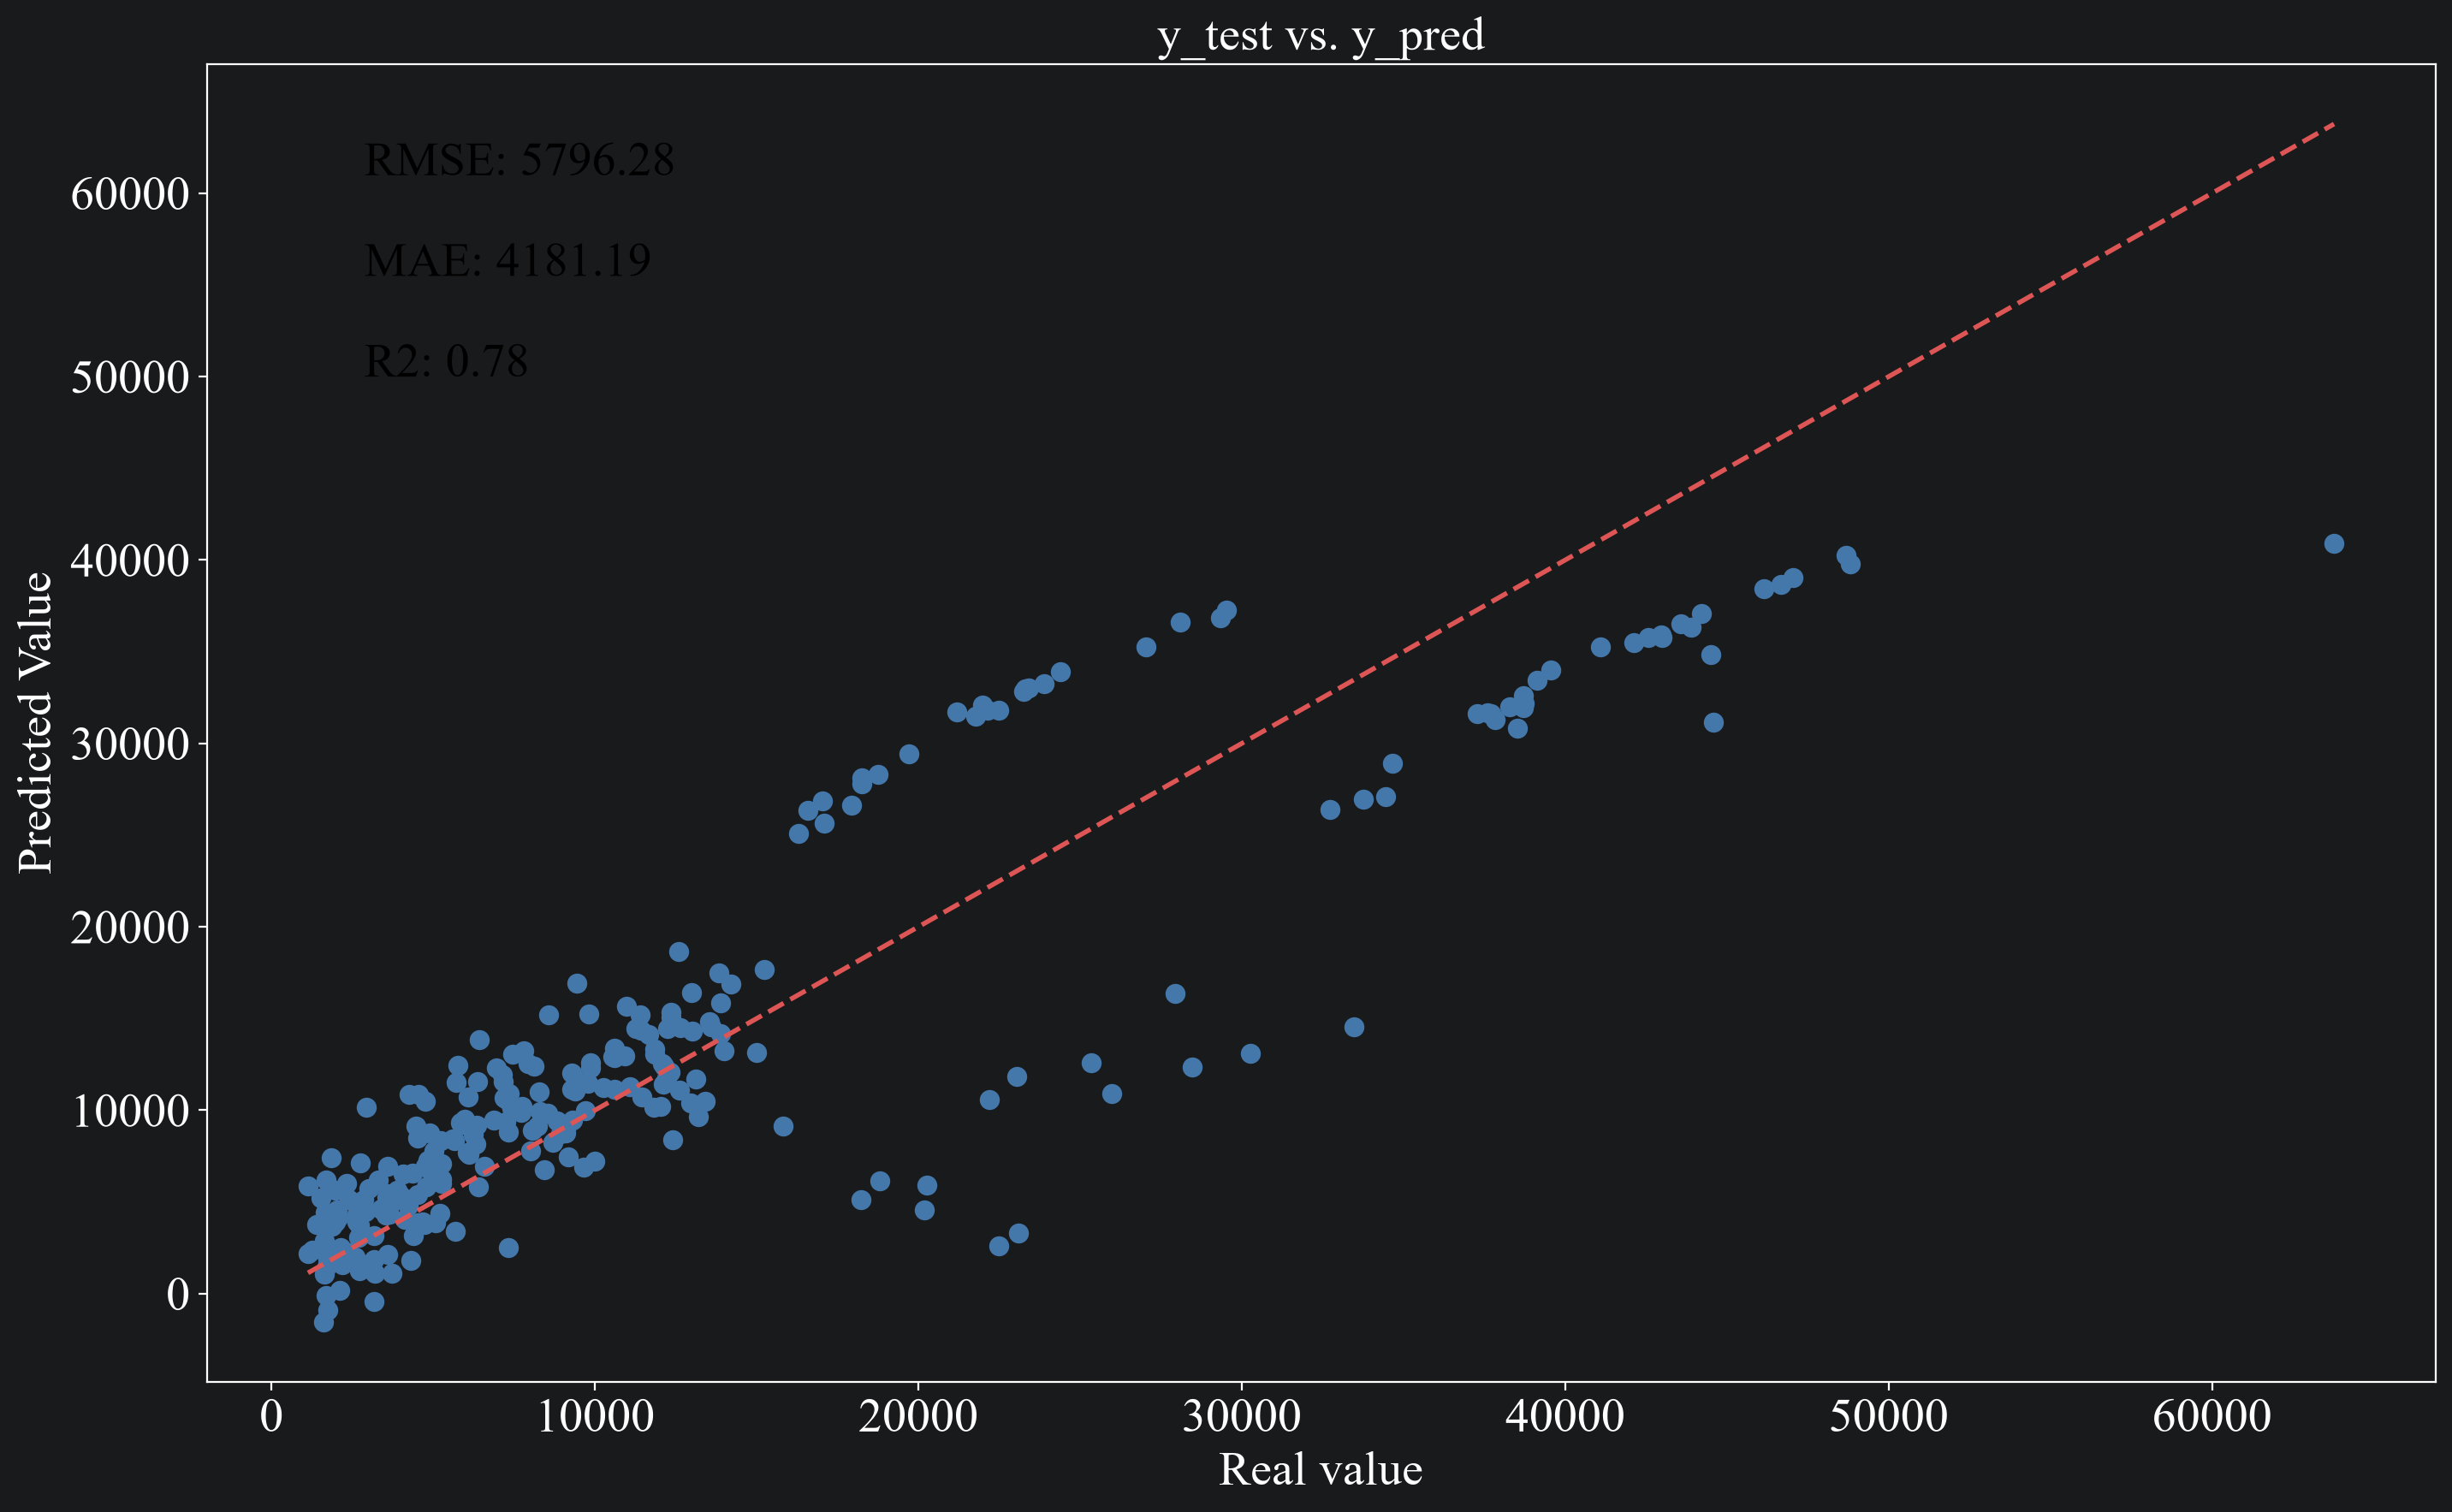

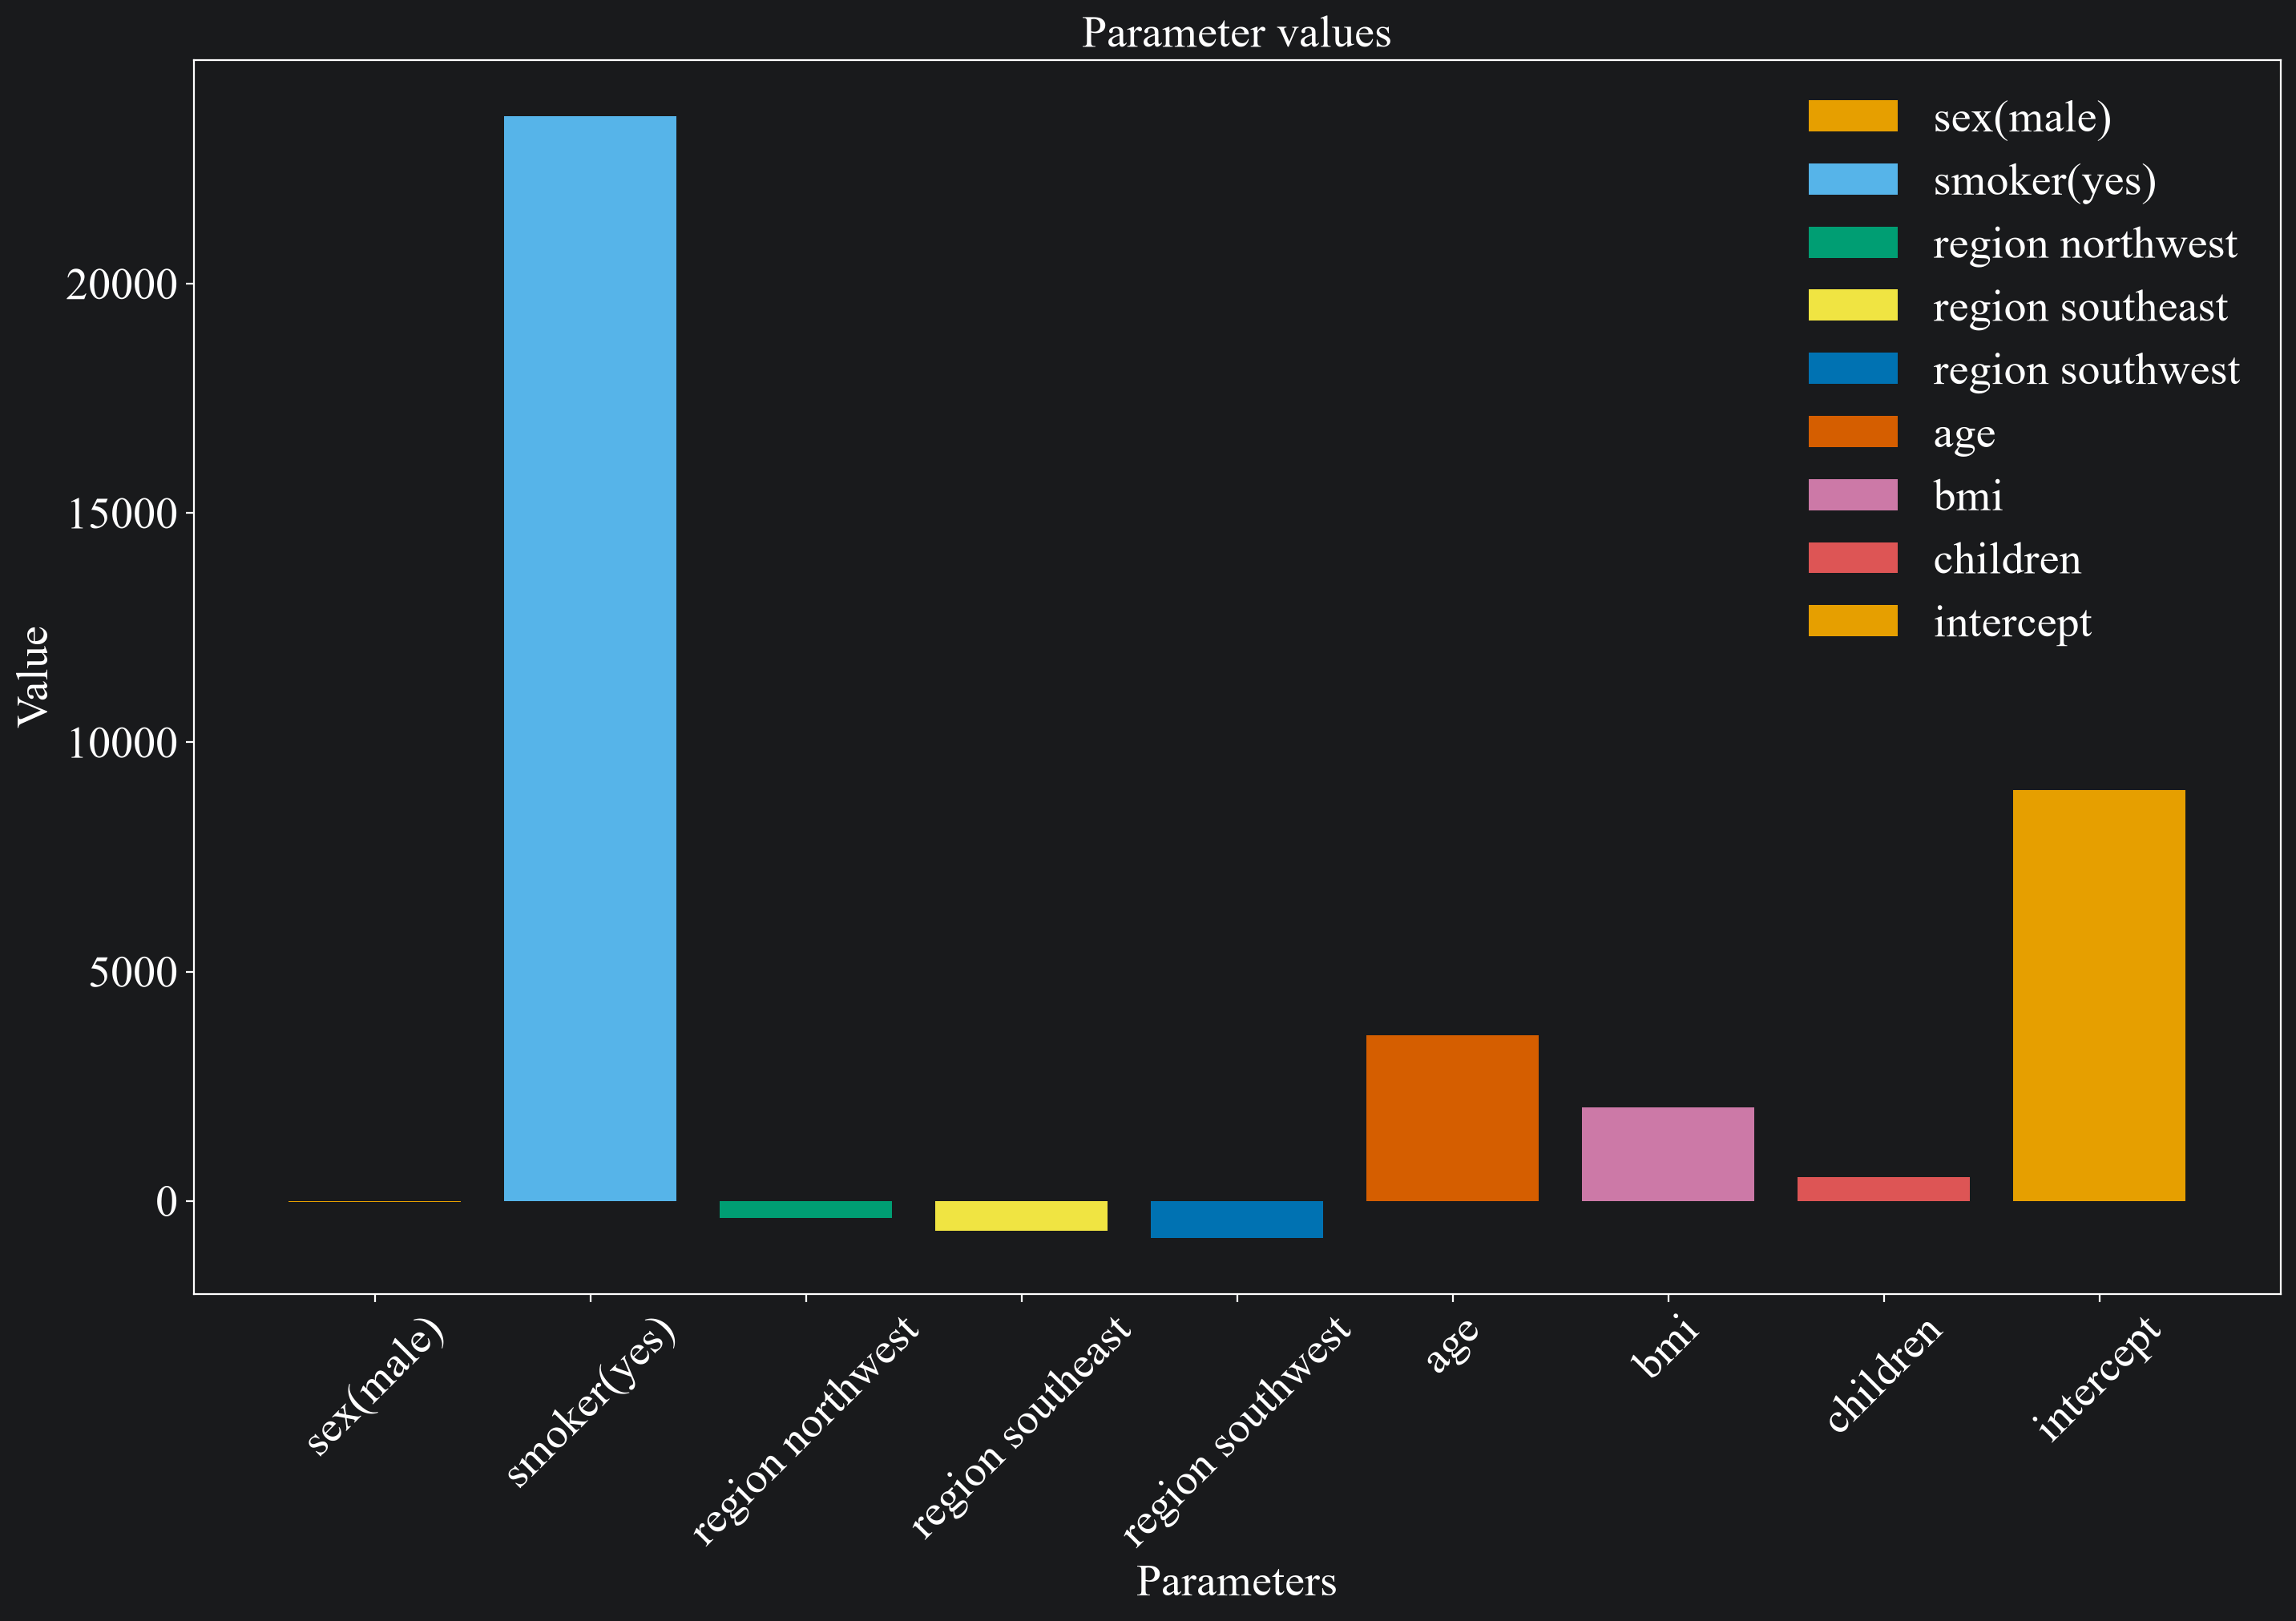

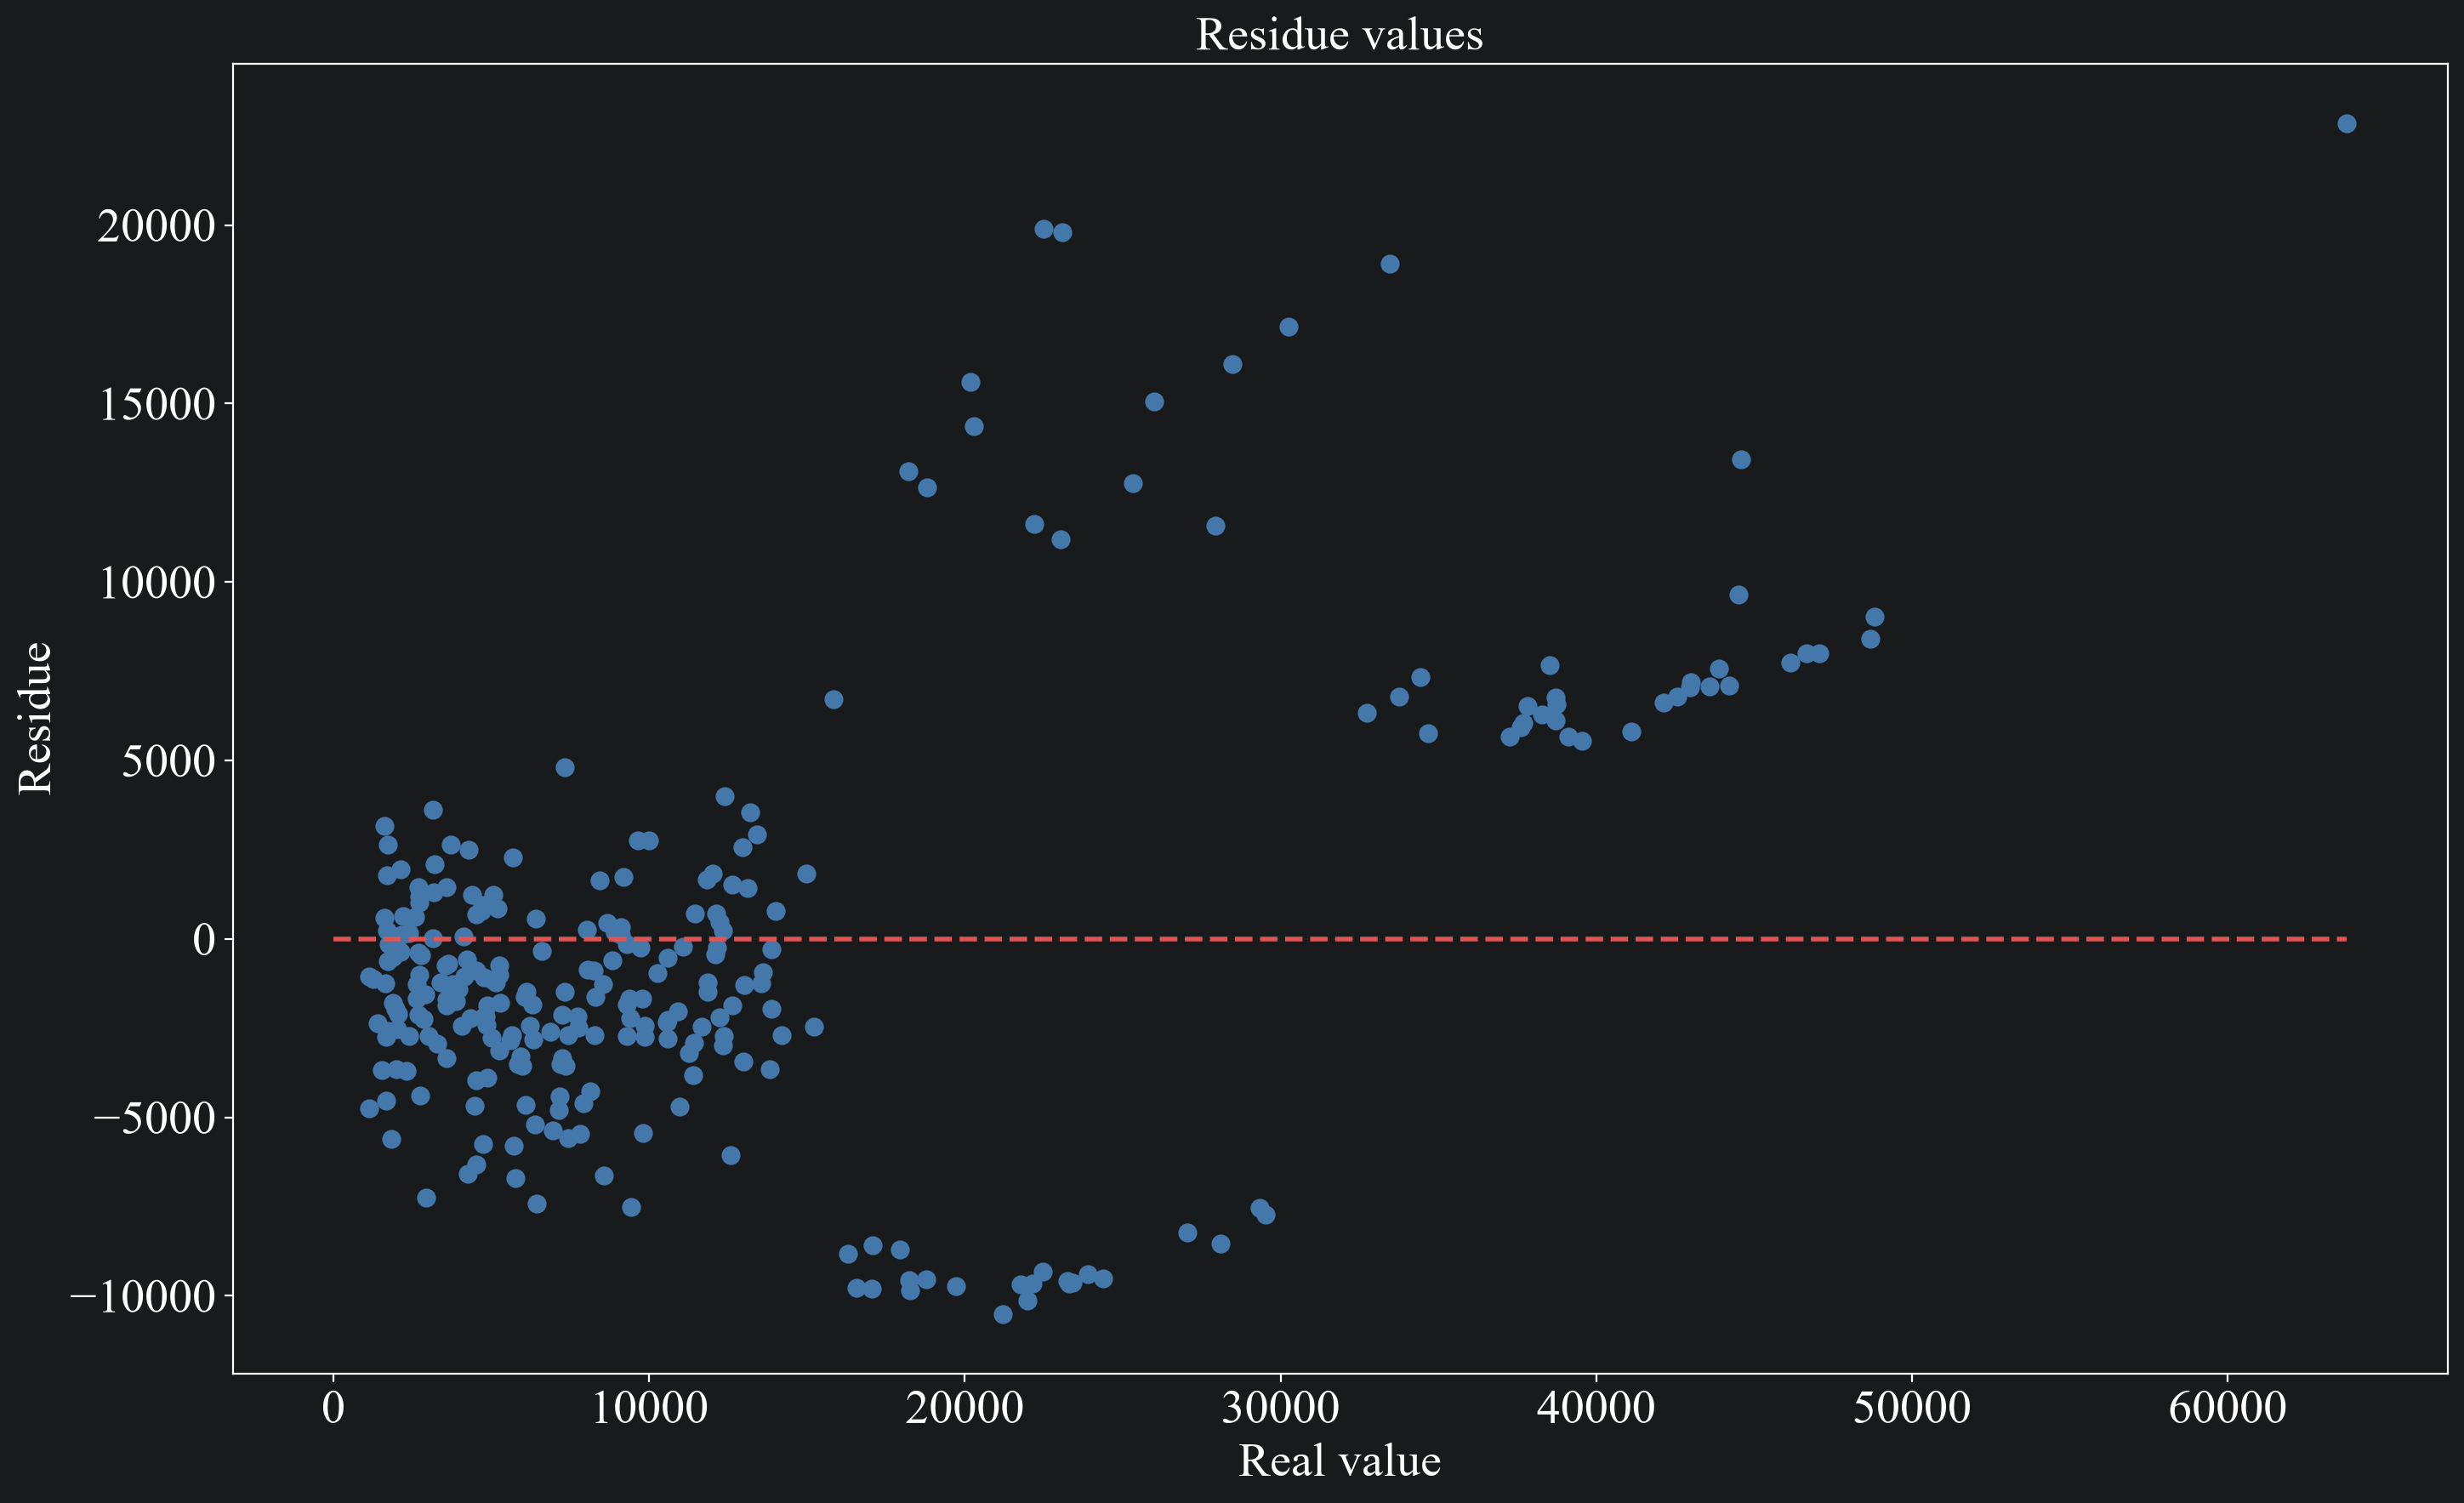

In [578]:
df = pd.read_csv(r"D:\machine_learning\Linear-Regression-GP-2-main\insurance.csv")  #读取文件

#区分分类值和连续值
cat_col = ['sex', 'smoker', 'region']
num_col = ['age', 'bmi', 'children']
#设置转换器，将标签值转换成数字，用于线性回归
ct = ColumnTransformer(
    transformers=[
    ('category', OneHotEncoder(sparse_output = False, drop = 'first'), cat_col),    #将分类值读热编码
    ('numerical', StandardScaler(), num_col)    #将连续值标准化
]
)
X = df[cat_col + num_col]   #设置特征值
y = df['charges']   #设置标签值

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)   #划分数据集
X_train_trans = ct.fit_transform(X_train)   #将训练集转化
X_test_trans = ct.transform(X_test) #将测试集转化

model = LinearRegression()  #实例化模型
model.fit(X_train_trans, y_train)   #训练模型
y_pred = model.predict(X_test_trans)    #模型预测

#交叉验证
cv_r2 = cross_val_score(model, X_train_trans, y_train, cv = 5, scoring = 'r2')  #交叉验证R**2值
cv_rmse = cross_val_score(model, X_train_trans, y_train, cv = 5, scoring = 'neg_root_mean_squared_error')   #交叉验证RMSE值
cv_mae = cross_val_score(model, X_train_trans, y_train, cv = 5, scoring = 'neg_mean_absolute_error')    #交叉验证MAE值

#评价模型
RMSE = root_mean_squared_error(y_test, y_pred)  #预RMSE
MAE = mean_absolute_error(y_test, y_pred)   #MAE
R2 = r2_score(y_test, y_pred)   #R**2
#将以上数值整理为表格
lis = pd.DataFrame([{
        'group' : 'cross-validation',
        'R2' : cv_r2.mean(),
        'RMSE' : -cv_rmse.mean(),
        'MAE' : -cv_mae.mean(),
    }
    ,
    {
        'group' : 'Test set',
        'R2' : R2,
        'RMSE' : RMSE,
        'MAE' : MAE,
    }
]
)
print(lis)  #输出表格

feature_name = ct.get_feature_names_out()   #提取特征名
coef = model.coef_  #提取每个特征的系数
dic = {}    #定义空字典
for name, coef in zip(feature_name, coef):  #将特征名和特征值保存进字典
    dic[name] = coef

dic['intercept'] = model.intercept_ #求截距并保存进字典
dic_ = pd.DataFrame.from_dict(dic, orient = 'index', columns = ['Parameters'])  #将字典保存为表格

#绘制y_test与y_pred对比图
fig, ax = plt.subplots(figsize = (16.8, 10), dpi = 200) #定义空画布和字典
ax.scatter(y_test, y_pred, s = 55, c = '#4477AA',)  #绘制散点图
x = np.linspace(min(y_test), max(y_test), 100)
y = x
ax.plot(x, y, linestyle = '--', color = '#DD5555', linewidth=2) #绘制对角线
ax.set_xlabel('Real value',fontsize = 20)   #设置横坐标名称
ax.set_ylabel('Predicted Value',fontsize = 20)  #设置纵坐标名称
ax.tick_params(axis='both', which='major', labelsize=20)    #设置横坐标大小
ax.set_title('y_test vs. y_pred', fontsize = 20)    #设置标题
ax.text(
        2500, 50000,    #设置文字位置
        f" RMSE: {RMSE:.2f} \n \n MAE: {MAE:.2f} \n \n R2: {R2:.2f}",   #显示文字
        fontsize=20, color="black", ha="left"   #设置文字的大小、坐标和颜色
        )   #显示RMSE、MAE和R**2
plt.savefig('D:/machine_learning/Linear-Regression-GP-2-main/1.png',bbox_inches='tight')
#下同

#绘制各个系数的图
fig2, ax2 = plt.subplots(figsize = (16.8, 10), dpi = 200)
label = ['sex(male)','smoker(yes)','region northwest','region southeast','region southwest','age','bmi','children','intercept'] #设置横坐标刻度名称
ax2.bar(
        dic_.index, dic_['Parameters'], #设置横坐标与纵坐标值
        color = ['#E69F00','#56B4E9','#009E73','#F0E442','#0072B2','#D55E00','#CC79A7','#DD5555'],  #设置柱状图颜色
        label = label
)
ax2.set_xlabel('Parameters',fontsize = 20)
ax2.set_xticks(ticks = np.arange(0,9),
               labels = label)
ax2.tick_params(axis = 'x', which = 'major', labelsize = 18, rotation = 45)
ax2.set_xlabel('Parameters',fontsize = 20)
ax2.set_ylabel('Value',fontsize = 20)
ax2.tick_params(axis='both', which='major', labelsize = 20)
ax2.legend(fontsize = 20,frameon = False)
ax2.set_title('Parameter values', fontsize = 20)
plt.savefig('D:/machine_learning/Linear-Regression-GP-2-main/2.png',bbox_inches='tight')

#绘制残差图
fig3, ax3 = plt.subplots(figsize = (16.8, 10), dpi = 200)
residual = y_test - y_pred  #计算残差
ax3.scatter(y_test, residual, color = '#4477AA', linewidth=2)
ax3.hlines(y = 0, xmin = 0, xmax = max(y_test), color = '#DD5555', linestyle = '--', linewidth = 2) #绘制y = 0图线
ax3.set_xlabel('Real value',fontsize = 20)
ax3.set_ylabel('Residue',fontsize = 20)
ax3.tick_params(axis='both', which='major', labelsize = 20)
ax3.set_title('Residue values', fontsize = 20)
plt.savefig('D:/machine_learning/Linear-Regression-GP-2-main/3.png',bbox_inches='tight')

print(dic_)
print(df.head())